In [2]:
#structure of the ppromps
import sys 
sys.path.insert(0,'../scripts/')
from prompter import Prompter
import ollama
import pandas as pd
import pickle
from tqdm import tqdm

In [ ]:
#we now process the results of each task
import sys 
sys.path.insert(0,'../scripts/')
from prompter import Prompter
import ollama
import pandas as pd
import pickle
from tqdm import tqdm
from pathlib import Path

# De-comment the task you want to do

# prefix=''
# input_name = 'final_sample_w_desc_cleaned' # balanced distant
# kw='end'
# t_folder = Path(f'../data/processed/df_processed/full_balanced_end_prompt')

# prefix='un'
# input_name = 'imbalanced_distant_label' # un-balanced distant
# kw='end'
# t_folder = Path(f'../data/processed/df_processed/full_balanced_end_prompt')

prefix='un'
input_name = 'imbalanced_test' # un-balanced manual
kw='end'
t_folder = Path(f'../data/processed/df_processed/full_unbalanced_end_prompt')


pd.options.mode.chained_assignment = None  # default='warn'

data = pd.DataFrame()
#t_folder = Path(f'../data/processed/df_processed/{prefix}balanced_seeds')
t_folder = Path(f'../data/processed/df_processed/full_{prefix}balanced_end_prompt')
folders = list(t_folder.iterdir())#the the seeds
models = ['llama3','mistral','gemma']
from nltk.tokenize import RegexpTokenizer
tokenizer = RegexpTokenizer(r'\w+')

df_seeds = {}
for seed_folder in folders:
    exp_folders = list(seed_folder.iterdir()) # the experiments
    df_set_experiment = {}#divided by prompt 
    #try:
    for folder in exp_folders:
        if folder.is_dir() and folder.name.endswith(kw):
            print(f"Reading: {folder}")
            df_dict_ = {} # divided by ablation
            if folder.name.endswith(kw):
                subfolders  =list(folder.iterdir())#the ablations 
                
                for subfolder in subfolders:
                    data= pd.DataFrame()
                    files = list(subfolder.iterdir())
                    j=0
                    for file in files:#for each model
                        if(not file.name.endswith('labeled.csv')):    
                            if j==0:
                                data= pd.read_csv(file)
                                data.drop('Unnamed: 0',axis=1,inplace=True)
                                #print(data.columns)
                            else:
                                data = pd.merge(left=data,right=pd.read_csv(file),left_on='id',right_on='id',how='inner')
                            j+=1
                            for column in data.columns:
                                if 'Unnamed' in column:
                                    data.drop(column,axis=1,inplace=True)
                    for model in models:
                        data[f'error_{model}'] = data[f'label_{model}'].apply(contains_non_binary) #-> we can measure how much the LLM can follow the instructions 
                        data[f'clean_{model}'] = data[f'label_{model}'].apply(extract_first_binary) #-> we can measure how much the LLM can follow the instructions 
                        data[f'clean_{model}'].fillna(-1,inplace=True)
                        data[f'clean_{model}'] = data[f'clean_{model}'].astype(int)
                        source = pd.read_csv(f'../data/processed/df_processed/{input_name}.csv')
                        source['token_text'] = source['whisper_cc'].apply(lambda x : tokenizer.tokenize(x))
                        source['text_length'] = source['token_text'].apply(lambda x : len(x))
                        #we add a column to the bins too identifiy the percentile
                        source['length_bins'] = pd.qcut(source['text_length'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])
                    data = pd.merge(left=data,right=source[['id','true_label','text_length','length_bins']],left_on='id',right_on='id',how='inner')
                    df_dict_[subfolder.name.split('/')[-1]] = data
            df_set_experiment[folder.name.split('/')[-1]] = df_dict_
    df_seeds[seed_folder.name.split('/')[-1]] = df_set_experiment
    # except:
    #     print(f'Error in reading folder: {seed_folder}')
    #     pass
    


In [314]:
#this in case you want to produce bins for the text lengths
source = pd.read_csv(f'../data/processed/df_processed/{input_name}.csv')
source['token_text'] = source['whisper_cc'].apply(lambda x : tokenizer.tokenize(x))
source['text_length'] = source['token_text'].apply(lambda x : len(x))
#we add a column to the bins too identifiy the percentile
source['length_bins'] = pd.qcut(source['text_length'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])

In [ ]:

# barplot data
import seaborn as sns 
import matplotlib.pyplot as plt
#fig = plt.figure(figsize=(8,5))
from sklearn.metrics import classification_report
j=0
models = ['llama3','mistral','gemma','ensemble']
test = pd.DataFrame()
for seed in list(df_seeds.keys()):
    for prompt in df_seeds[seed].keys():
        for ablation in df_seeds[seed][prompt].keys():
            for model in models:
                
                if model == 'ensemble':
                    testing = pd.DataFrame()
                    testing['majority_number'] = (df_seeds[seed][prompt][ablation]['clean_gemma']*0.33+df_seeds[seed][prompt][ablation]['clean_llama3']*0.33+df_seeds[seed][prompt][ablation]['clean_mistral']*0.33)
                    testing['majority_label'] = testing['majority_number'].apply(lambda x : 1 if x >=0.5 else 0)
                    testing['true_label'] = df_seeds[seed][prompt][ablation]['true_label']
                    temp = pd.DataFrame.from_dict(classification_report( testing['true_label'], testing['majority_label'],output_dict=True)).pivot_table(columns=['precision','recall','f1-score','support']).reset_index()
                else:
                    temp = pd.DataFrame.from_dict(classification_report( df_seeds[seed][prompt][ablation]['true_label'], df_seeds[seed][prompt][ablation][f'clean_{model}'],output_dict=True)).pivot_table(columns=['precision','recall','f1-score','support']).reset_index()
                #print(temp)
                #temp.drop(temp[temp.])
                temp['hue'] = model
                temp['ablation'] = ablation
                temp['seed'] = seed
                temp['prompt'] = prompt
                test = pd.concat([test,temp])
test['label'] = test['index']
test.drop('index',inplace=True,axis=1)
test.reset_index(inplace=True)
test.drop(test[test['label'] != '1'].index,inplace=True,axis = 0)


In [ ]:

#data for text length performance
import seaborn as sns 
import matplotlib.pyplot as plt
#fig = plt.figure(figsize=(8,5))
from sklearn.metrics import classification_report
j=0
models = ['llama3','mistral','gemma','ensemble']
quarts = ['Q1', 'Q2', 'Q3', 'Q4']
test = pd.DataFrame()
for seed in list(df_seeds.keys()):
    for prompt in df_seeds[seed].keys():
        for ablation in df_seeds[seed][prompt].keys():
            for quart in quarts:
                for model in models:
                    testing = pd.DataFrame.from_dict(df_seeds[seed][prompt][ablation])
                    if model == 'ensemble':
                        testing_local = pd.DataFrame()
                        testing_local['majority_number'] = (testing[testing['length_bins'] == quart]['clean_gemma']*0.33+testing[testing['length_bins'] == quart]['clean_llama3']*0.33+testing[testing['length_bins'] == quart]['clean_mistral']*0.33)
                        testing_local['majority_label'] = testing_local['majority_number'].apply(lambda x : 1 if x >=0.5 else 0)
                        testing_local['true_label'] = testing[testing['length_bins'] == quart]['true_label']
                        temp = pd.DataFrame.from_dict(classification_report( testing_local['true_label'], testing_local['majority_label'],output_dict=True)).pivot_table(columns=['precision','recall','f1-score','support']).reset_index()
                    else:
                        temp = pd.DataFrame.from_dict(classification_report( testing[testing['length_bins'] == quart]['true_label'], testing[testing['length_bins'] == quart][f'clean_{model}'],output_dict=True)).pivot_table(columns=['precision','recall','f1-score','support']).reset_index()
                        #print(temp)
                        #temp.drop(temp[temp.])
                    temp['hue'] = model
                    temp['ablation'] = ablation
                    temp['seed'] = seed
                    temp['prompt'] = prompt
                    temp['quarter'] = quart
                    test = pd.concat([test,temp])
test['label'] = test['index']
test.drop('index',inplace=True,axis=1)
test.reset_index(inplace=True)
test.drop(test[test['label'] != '1'].index,inplace=True,axis = 0)


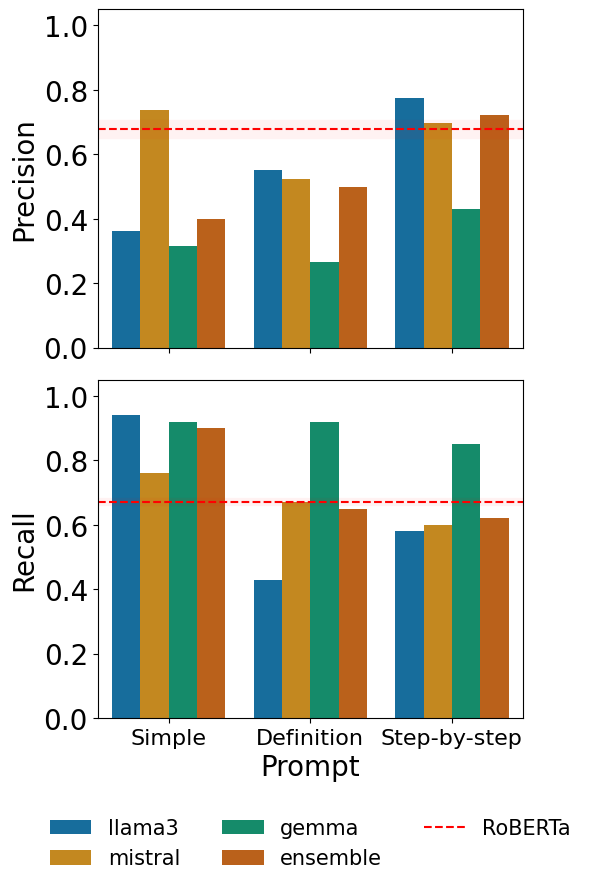

In [221]:
#print(test)

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
import seaborn as sns

plt.rc('axes', labelsize=20) #fontsize of the x and y labels
plt.rc('xtick', labelsize=16) #fontsize of the x tick labels
plt.rc('ytick', labelsize=20) #fontsize of the y tick labels
plt.rc('legend', fontsize=15) #fontsize of the legend
j=0
fig,axes  = plt.subplots(2, figsize=(6,9),tight_layout=True,sharex = True)

test['Precision'] = test['precision']
test['Recall']  = test['recall']

measures= ['Precision','Recall']
hue_order = ['simple_prompt_end','definition_prompt_end','sbs_prompt_end']
for measure in measures:
    sns.barplot(
        data=test, 
        x="prompt", y=measure, hue="hue",
        errorbar="sd", palette="colorblind", alpha=1,legend = True if j>0 else False,fill=True,dodge=True,ax=axes[j],order=hue_order
        
    )
    # axes[j].set_title(names[j])
    axes[j].set_ylim(0,1.05)
    axes[j].set_xlabel('Prompt')
    axes[j].set_ylabel(measure)

    axes[j].set_xticks([0,1,2],['Simple','Definition','Step-by-step'])
    #hardcoded data since we calculated these ranges from results of another notebook
    if measure == 'Precision':
        if prefix == '':
            n,l,h,lw = 0.83,0.81,0.84,6
        else:
            n,l,h,lw = 0.68,0.72,0.64,14
    else:
        if prefix == '':
            n,l,h,lw = 0.83,0.81,0.84,6
        else:
            n,l,h,lw = 0.67,0.66,0.68,6

    axes[j].axhline(y=n, color='r', linestyle='--',label='RoBERTa')

    axes[j].axhline(y= n, color='r', lw=lw,alpha=0.05,label=None)

    if j==1:    
        L =  plt.legend(title=f'{prefix}balanced dataset', loc='center right',bbox_to_anchor=(1.6, 0.5),ncol=1)

        handles, labels = plt.gca().get_legend_handles_labels()
        
        plt.legend(handles=handles,title=f'', loc='lower center',bbox_to_anchor=(0.5, -0.5),ncol=3,frameon=False)
        


    j+=1
    plt.savefig(f"../img/vertical_rq3_manual_{prefix}balanced.pdf", format="pdf", bbox_inches="tight")

## Calc the cohen's K between distant label and Manual


In [415]:
from sklearn.metrics import *
cohen = pd.read_csv('../data/tmp/Cohens_validation_sample_100_cc_ - validation_sample_100_cc_ (2).csv')
cohen = cohen[['true_label','original label']]
print(cohen[['true_label','original label']])
cohen_kappa_score(cohen['true_label'].to_list(), cohen['original label'].to_list())

     true_label  original label
0             0               1
1             1               1
2             1               1
3             1               1
4             1               1
..          ...             ...
198           0               0
199           0               0
200           0               0
201           0               0
202           0               0

[203 rows x 2 columns]


0.8132836326668926

---
### We calculate now the distribution of lenghts of text

In [355]:
df = pd.read_csv(f'../data/processed/df_processed/imbalanced_distant_label.csv') # always the same dataset


In [356]:
from nltk.tokenize import RegexpTokenizer
tokenizer = RegexpTokenizer(r'\w+')


df['token_text'] = df['whisper_cc'].apply(lambda x : tokenizer.tokenize(x))
df['text_length'] = df['token_text'].apply(lambda x : len(x))

In [357]:
df[df['true_label']== 1]['text_length'].describe()

count     119.000000
mean      373.747899
std       272.169601
min        11.000000
25%       213.000000
50%       341.000000
75%       441.500000
max      1919.000000
Name: text_length, dtype: float64

/tmp/ipykernel_543602/450801213.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data = df, y = 'true_label', x='text_length', orient='h',width = .5,palette=sns.color_palette('colorblind'))
/tmp/ipykernel_543602/450801213.py:5: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  sns.boxplot(data = df, y = 'true_label', x='text_length', orient='h',width = .5,palette=sns.color_palette('colorblind'))


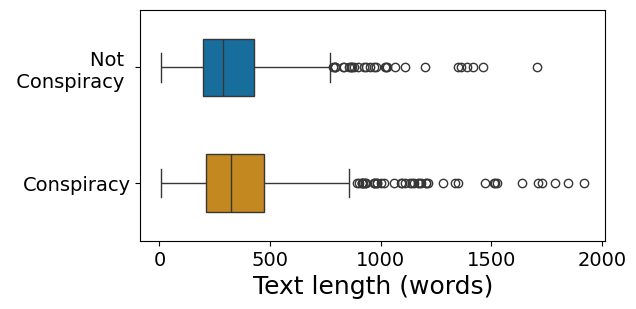

In [342]:
import seaborn as sns
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(6,3))
sns.boxplot(data = df, y = 'true_label', x='text_length', orient='h',width = .5,palette=sns.color_palette('colorblind'))
plt.xlabel('Text length (words)')
plt.ylabel('')
plt.yticks([0,1],['Not \n Conspiracy ' , 'Conspiracy'])
plt.savefig(f"../img/durations_classes.pdf", format="pdf", bbox_inches="tight")


In [346]:
from scipy.stats import mannwhitneyu

mannwhitneyu(df[df['true_label'] == 0 ]['text_length'],df[df['true_label'] == 1]['text_length'],nan_policy='omit')

MannwhitneyuResult(statistic=315984.0, pvalue=0.002601852121342884)

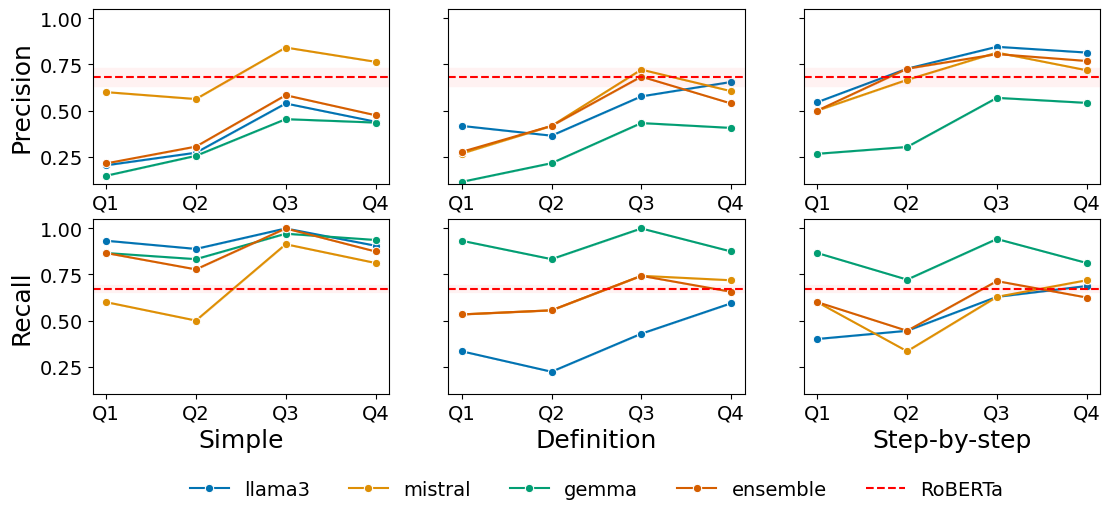

In [349]:
#print(test)

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
import seaborn as sns

plt.rc('axes', labelsize=18) #fontsize of the x and y labels
plt.rc('xtick', labelsize=14) #fontsize of the x tick labels
plt.rc('ytick', labelsize=14) #fontsize of the y tick labels
plt.rc('legend', fontsize=14) #fontsize of the legend
j=0

fig,axes  = plt.subplots(figsize =(13,5) ,nrows=2, ncols=3,sharey = True)

test['Precision'] = test['precision']
test['Recall']  = test['recall']

measures= ['Precision','Recall']
hue_order = ['simple_prompt_end','definition_prompt_end','sbs_prompt_end']
for measure in measures:
    k=0
    for prompt in hue_order:
        sns.lineplot(
            data=test[test['prompt'] == prompt], 
            x='quarter', y=measure, hue="hue",
            palette="colorblind", alpha=1,legend = True if j==1 and k==1 else False,ax=axes[j][k],
            marker= 'o'
        )
        axes[j][k].set_ylim(0.1,1.05)
        # axes[j].set_ylabel('Metrics value')
        axes[j][k].set_xlabel('')
        axes[j][k].set_ylabel(measure)

        #axes[j][k].set_xticks([0,1,2],['S','D','SBS'])
        if measure == 'Precision':
            if prefix == '':
                n,l,h,lw = 0.83,0.81,0.84,6
            else:
                n,l,h,lw = 0.68,0.72,0.64,14
        else:
            if prefix == '':
                n,l,h,lw = 0.83,0.81,0.84,6
            else:
                n,l,h,lw = 0.67,0.66,0.68,6

        axes[j][k].axhline(y=n, color='r', linestyle='--',label='RoBERTa')


        axes[j][k].axhline(y= n, color='r', lw=lw,alpha=0.05,label=None)

        if j==1: 
            if k == 0 :
                axes[j][k].set_xlabel('Simple')
            else:
                axes[j][k].set_xlabel('Step-by-step')
            if k == 1:   
                #L =  plt.legend(title=f'', loc='lower center',bbox_to_anchor=(1.6, 0.5),ncol=4)
                axes[j][k].set_xlabel('Definition')
                handles, labels = axes[j][k].get_legend_handles_labels()
                
                axes[j][k].legend(handles=handles,labels = labels,title=f'', loc='lower center',bbox_to_anchor=(0.5, -0.7),ncol=5,frameon=False)
        k+=1
    j+=1

#fig.tight_layout()
plt.savefig(f"../img/grid_rq4_manual_{prefix}balanced.pdf", format="pdf", bbox_inches="tight")